In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder,StandardScaler,QuantileTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score,recall_score,precision_score,r2_score
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.neighbors import KNeighborsRegressor,KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

In [22]:
df = pd.read_csv(r"C:\Users\aahan\Self\Coding\Kaggle\Diabetes\diabetes_prediction_dataset.csv")
df.head(10)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
5,Female,20.0,0,0,never,27.32,6.6,85,0
6,Female,44.0,0,0,never,19.31,6.5,200,1
7,Female,79.0,0,0,No Info,23.86,5.7,85,0
8,Male,42.0,0,0,never,33.64,4.8,145,0
9,Female,32.0,0,0,never,27.32,5.0,100,0


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [24]:
df.shape

(100000, 9)

In [25]:
df.isna().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [26]:
df.tail(10)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
99990,Male,39.0,0,0,No Info,27.32,6.1,100,0
99991,Male,22.0,0,0,current,29.65,6.0,80,0
99992,Female,26.0,0,0,never,34.34,6.5,160,0
99993,Female,40.0,0,0,never,40.69,3.5,155,0
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0
99999,Female,57.0,0,0,current,22.43,6.6,90,0


In [35]:
X, y = df.drop(columns="diabetes"), df["diabetes"]

In [58]:
num_cols = X.select_dtypes("number").columns
cat_cols = ["gender", "smoking_history"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(class_weight="balanced",max_iter=1000))
])

In [59]:
model = GridSearchCV(
    estimator=pipe,
    param_grid={"model__class_weight": [{0: 1, 1: 2}, {0: 1, 1: 5}, "balanced"]},
    cv=3,
    scoring={"f1": "f1", "recall": "recall", "roc_auc": "roc_auc"},
    refit="f1",
    n_jobs=-1
)
model.fit(X, y)

,estimator,Pipeline(step..._iter=1000))])
,param_grid,"{'model__class_weight': [{0: 1, 1: 2}, {0: 1, 1: 5}, ...]}"
,scoring,"{'f1': 'f1', 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,n_jobs,-1
,refit,'f1'
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [61]:
pd.DataFrame(model.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__class_weight,params,split0_test_f1,split1_test_f1,split2_test_f1,mean_test_f1,std_test_f1,rank_test_f1,split0_test_recall,split1_test_recall,split2_test_recall,mean_test_recall,std_test_recall,rank_test_recall,split0_test_roc_auc,split1_test_roc_auc,split2_test_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,1.026983,0.073778,0.459587,0.149294,"{0: 1, 1: 2}","{'model__class_weight': {0: 1, 1: 2}}",0.732000,0.725364,0.717372,0.724912,0.005981,1,0.710303,0.695023,0.697494,0.700940,0.006697,3,0.963299,0.959772,0.963018,0.962030,0.001601,3
1,1.288238,0.196345,0.600222,0.166271,"{0: 1, 1: 5}","{'model__class_weight': {0: 1, 1: 5}}",0.658766,0.661224,0.655647,0.658546,0.002282,2,0.804164,0.800565,0.798094,0.800941,0.002492,2,0.963381,0.959937,0.963176,0.962165,0.001578,2
2,1.277122,0.189342,0.552698,0.068884,balanced,{'model__class_weight': 'balanced'},0.574078,0.567949,0.570812,0.570946,0.002504,3,0.884615,0.872573,0.886340,0.881176,0.006124,1,0.963376,0.959970,0.963204,0.962183,0.001567,1


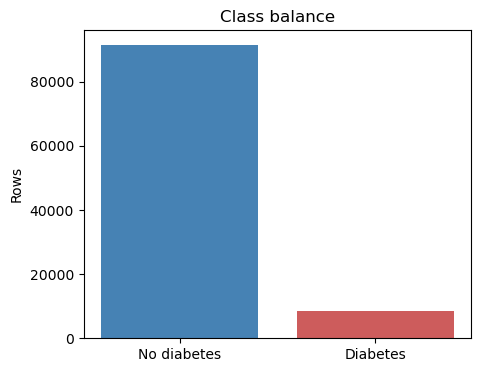

In [63]:
counts = df["diabetes"].value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["No diabetes", "Diabetes"], [counts[0], counts[1]], color=["steelblue", "indianred"])
ax.set_title("Class balance")
ax.set_ylabel("Rows")
plt.show()

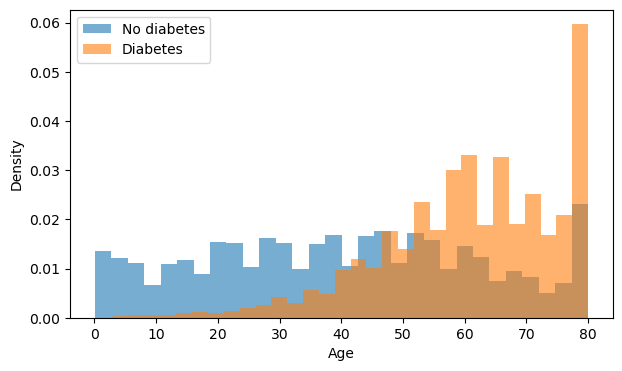

In [64]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, name in [(0, "No diabetes"), (1, "Diabetes")]:
    ax.hist(df.loc[df["diabetes"] == label, "age"], bins=30, alpha=0.6, density=True, label=name)
ax.set_xlabel("Age"); ax.set_ylabel("Density"); ax.legend()
plt.show()

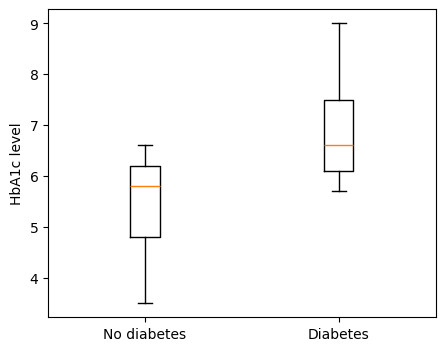

In [65]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([df.loc[df["diabetes"] == 0, "HbA1c_level"],
            df.loc[df["diabetes"] == 1, "HbA1c_level"]])
ax.set_xticklabels(["No diabetes", "Diabetes"])
ax.set_ylabel("HbA1c level")
plt.show()

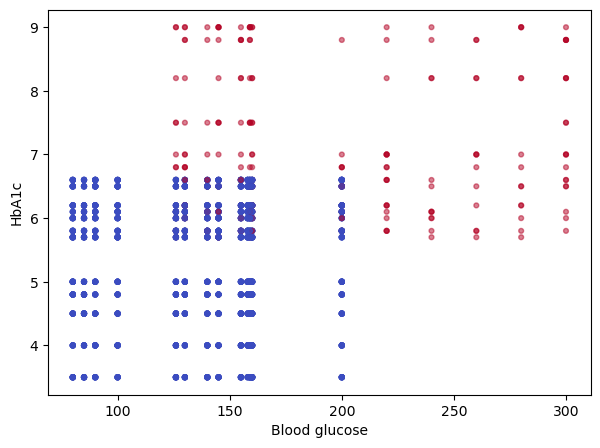

In [66]:
s = df.sample(3000, random_state=42)     # 100k points is unreadable and slow
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(s["blood_glucose_level"], s["HbA1c_level"], c=s["diabetes"],
                cmap="coolwarm", alpha=0.5, s=12)
ax.set_xlabel("Blood glucose"); ax.set_ylabel("HbA1c")
plt.show()

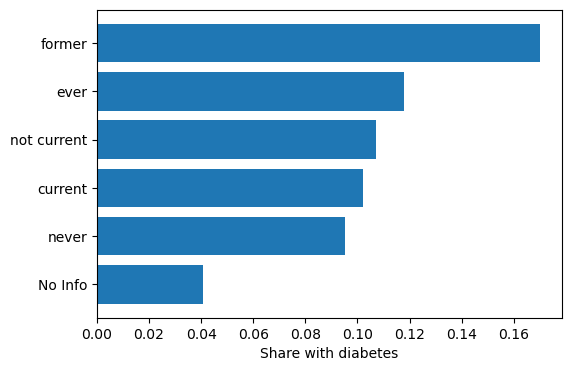

In [67]:
rate = df.groupby("smoking_history")["diabetes"].mean().sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(rate.index, rate.values)
ax.set_xlabel("Share with diabetes")
plt.show()

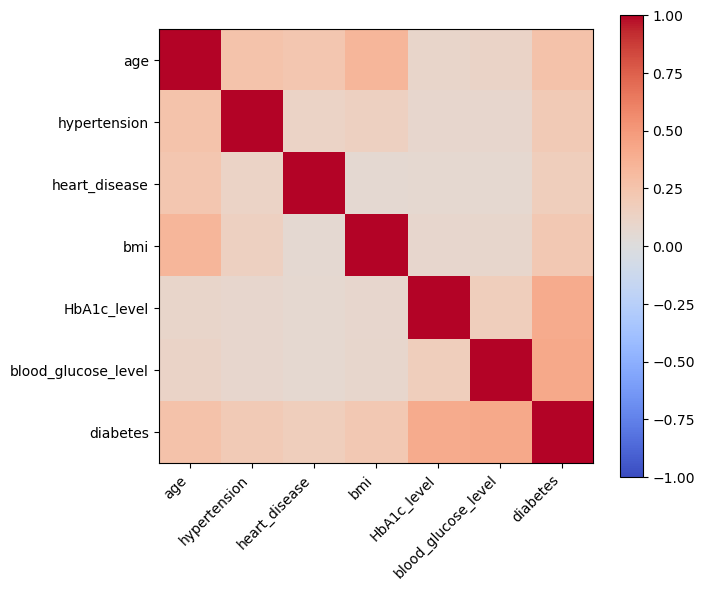

In [68]:
corr = df.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
fig.colorbar(im)
plt.show()

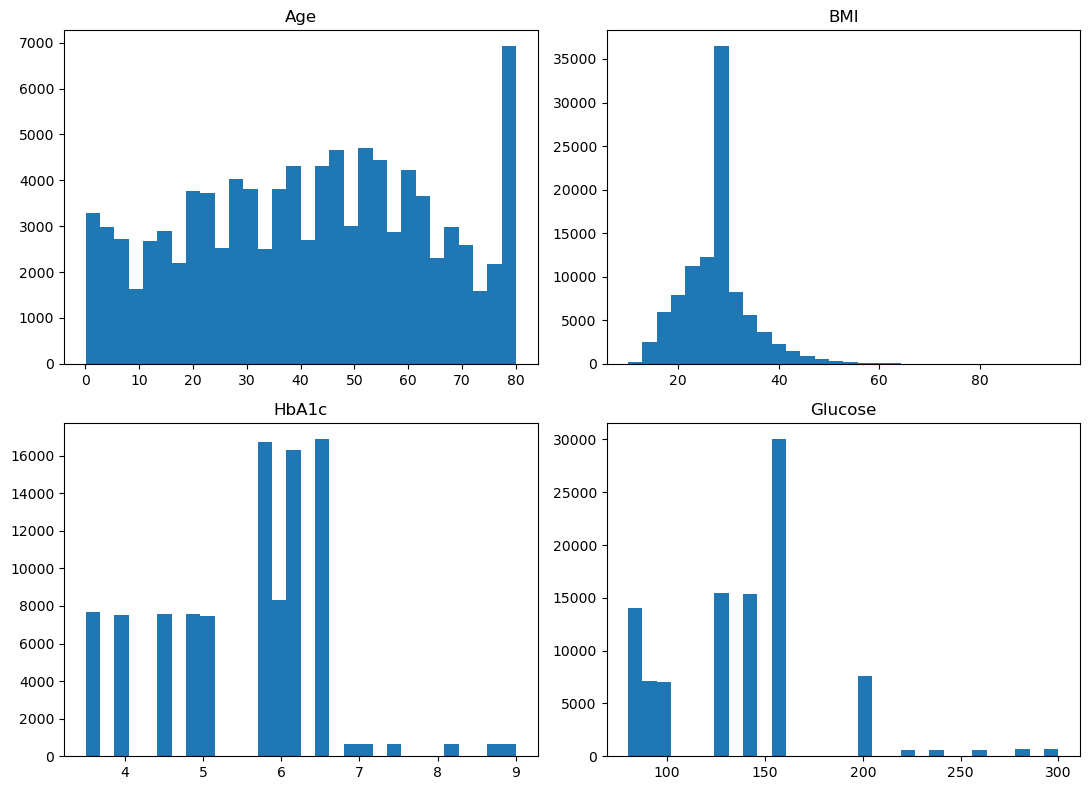

In [69]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist(df["age"], bins=30);          axes[0, 0].set_title("Age")
axes[0, 1].hist(df["bmi"], bins=30);          axes[0, 1].set_title("BMI")
axes[1, 0].hist(df["HbA1c_level"], bins=30);  axes[1, 0].set_title("HbA1c")
axes[1, 1].hist(df["blood_glucose_level"], bins=30); axes[1, 1].set_title("Glucose")
fig.tight_layout()
plt.show()

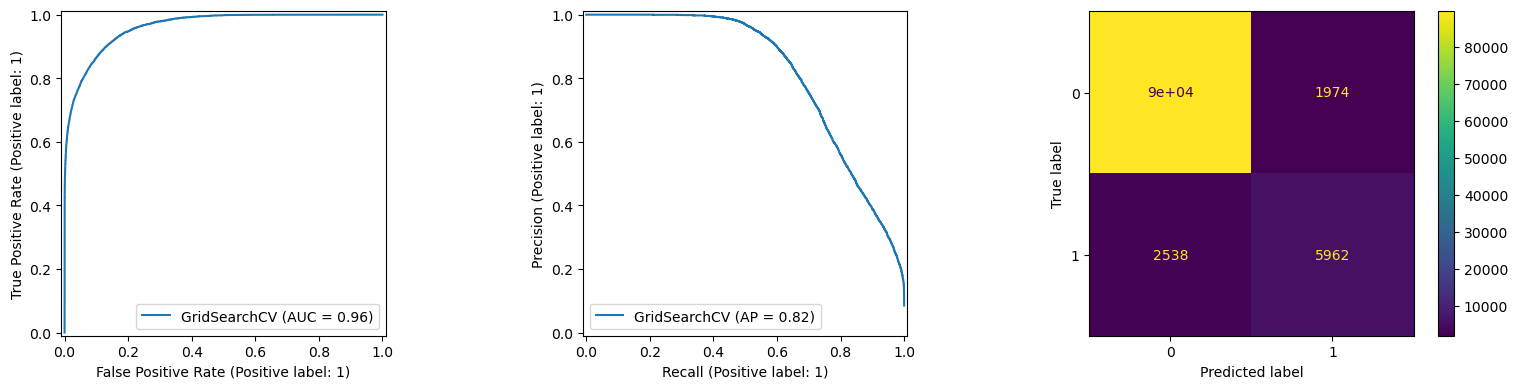

In [70]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
RocCurveDisplay.from_estimator(model, X, y, ax=axes[0])
PrecisionRecallDisplay.from_estimator(model, X, y, ax=axes[1])
ConfusionMatrixDisplay.from_estimator(model, X, y, ax=axes[2])
fig.tight_layout()
plt.show()